# Notebook 4 — Feature-Based Ranker and Optuna Tuning

The improved ranker combines semantic similarity, lexical similarity, temporal applicability, document status, approval, authority, recency, and structural features. A random-forest classifier learns document relevance from the training split. Optuna selects hyperparameters using development-set mean reciprocal rank. The frozen test split remains untouched.

In [1]:
from pathlib import Path
import json, sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
(ROOT / 'results' / 'figures').mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('Frozen test split accessed:', False)

Project root: <PROJECT_ROOT>
Frozen test split accessed: False


In [2]:
import json, joblib
import optuna
import pandas as pd
from src.local_pipeline import FEATURE_NAMES, build_pair_features, fit_ranker, ranker_results

optuna.logging.set_verbosity(optuna.logging.WARNING)
bundle = build_pair_features(ROOT, ('train', 'development'))
features = bundle.frame
features.to_csv(ROOT / 'results' / 'pair_features_train_development.csv', index=False)
train = features[features['split'] == 'train'].copy()
development = features[features['split'] == 'development'].copy()
{'training_pairs': len(train), 'development_pairs': len(development), 'positive_training_pairs': int(train['label'].sum()), 'features': FEATURE_NAMES}

{'training_pairs': 4320,
 'development_pairs': 2160,
 'positive_training_pairs': 66,
 'features': ['dense_similarity',
  'lexical_similarity',
  'token_overlap',
  'model_id_match',
  'effective_on_question_date',
  'current_document',
  'superseded_document',
  'approved_document',
  'authority_score',
  'recency_score',
  'document_length_log']}

In [3]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 120, 420, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 14),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 8),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.7, 1.0]),
        'class_weight': trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample']),
    }
    model = fit_ranker(train, params)
    metrics, _ = ranker_results(model, development, top_k=5)
    return metrics['mean_reciprocal_rank']

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=699))
study.optimize(objective, n_trials=25)
best_params = study.best_params
best_model = fit_ranker(train, best_params)
dev_metrics, dev_rows = ranker_results(best_model, development, top_k=5)
joblib.dump(best_model, ROOT / 'results' / 'optuna_ranker.joblib')
(ROOT / 'results' / 'optuna_best_params.json').write_text(json.dumps(best_params, indent=2) + '\n')
(ROOT / 'results' / 'optuna_development_metrics.json').write_text(json.dumps(dev_metrics, indent=2) + '\n')
{'best_value_mrr': study.best_value, 'best_params': best_params, 'development_metrics': dev_metrics}

{'best_value_mrr': 0.958333,
 'best_params': {'n_estimators': 220,
  'max_depth': 3,
  'min_samples_leaf': 5,
  'max_features': 0.7,
  'class_weight': 'balanced_subsample'},
 'development_metrics': {'hit_rate_at_5': 1.0,
  'recall_at_5': 0.979167,
  'precision_at_5': 0.291667,
  'mean_reciprocal_rank': 0.958333,
  'answerable_questions': 24,
  'unanswerable_questions_excluded_from_retrieval_metrics': 6,
  'by_category': {'direct_retrieval': {'questions': 6, 'hit_rate_at_5': 1.0},
   'cross_document_synthesis': {'questions': 6, 'hit_rate_at_5': 1.0},
   'temporal_update': {'questions': 6, 'hit_rate_at_5': 1.0},
   'conflicting_evidence': {'questions': 6, 'hit_rate_at_5': 1.0},
   'unanswerable_abstention': {'questions': 6, 'hit_rate_at_5': None}}}}

,number,value,state
12,12,0.958333,COMPLETE
8,8,0.958333,COMPLETE
22,22,0.958333,COMPLETE
21,21,0.958333,COMPLETE
14,14,0.958333,COMPLETE
11,11,0.958333,COMPLETE
24,24,0.958333,COMPLETE
1,1,0.937500,COMPLETE
2,2,0.854167,COMPLETE
20,20,0.843750,COMPLETE


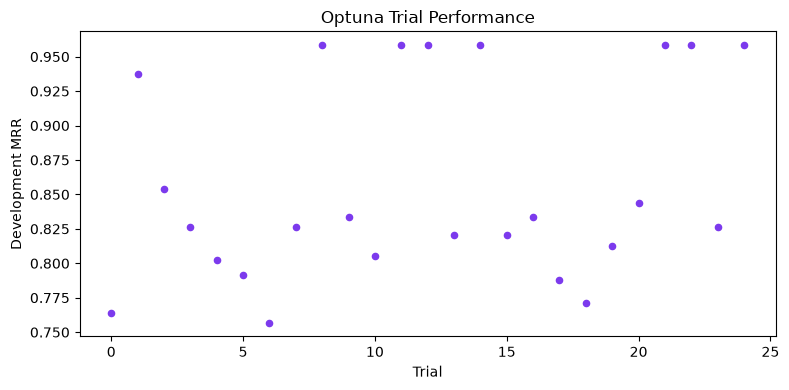

In [4]:
trials = study.trials_dataframe()
display(trials[['number', 'value', 'state']].sort_values('value', ascending=False).head(10))
ax = trials.plot.scatter(x='number', y='value', figsize=(8, 4), color='#7C3AED')
ax.set_title('Optuna Trial Performance'); ax.set_xlabel('Trial'); ax.set_ylabel('Development MRR')
ax.figure.tight_layout()
ax.figure.savefig(ROOT / 'results' / 'figures' / 'optuna_trials.png', dpi=180, bbox_inches='tight')

## Methodological note

Optuna tunes only model hyperparameters; it does not alter labels or inspect test questions. The development score is therefore a model-selection estimate, not the final unbiased performance estimate. Final evaluation must occur once on the frozen test split after the pipeline is locked.